# Jupyter Analytics Workflow — Lab 7
**Data Analyst Internship · Task 4 · Tool Mastery Project**

This notebook combines the core Python analytical techniques used by a working Data Analyst: data loading, cleaning, transformation, exploratory analysis, visualisation and statistical summary — all in one reproducible document.

**Dataset:** `data/online_retail_sales_sample.csv` — 12,177 real transaction lines from the UCI *Online Retail* dataset (DOI [10.24432/C5BW33](https://doi.org/10.24432/C5BW33)).

## 1. Environment and reproducibility
The kernel, package versions and random seed are fixed up front so that every run produces identical numbers.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {stats.__name__}")
print(f"random state = {RANDOM_STATE}")

numpy 2.3.5 | pandas 2.2.3 | scipy scipy.stats
random state = 42


## 2. Load the data
`pd.read_csv` with explicit dtypes and date parsing. Explicit dtypes stop pandas guessing, which matters when invoice numbers look numeric.

In [2]:
DATA = "../data/online_retail_sales_sample.csv"
raw = pd.read_csv(DATA, parse_dates=["InvoiceDate"],
                  dtype={"InvoiceNo": str, "StockCode": str})
print(f"shape : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"memory: {raw.memory_usage(deep=True).sum() / 1024:.1f} KB")
raw.head()

shape : 12,177 rows x 9 columns
memory: 3410.1 KB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,line_total
0,536572,21523,DOORMAT FANCY FONT HOME SWEET HOME,10,2010-12-01 15:40:00,6.75,"16,539.00",United Kingdom,67.50
1,536572,21754,HOME BUILDING BLOCK WORD,6,2010-12-01 15:40:00,5.95,"16,539.00",United Kingdom,35.70
2,536572,21756,BATH BUILDING BLOCK WORD,3,2010-12-01 15:40:00,5.95,"16,539.00",United Kingdom,17.85
3,536572,21810,CHRISTMAS HANGING STAR WITH BELL,12,2010-12-01 15:40:00,1.25,"16,539.00",United Kingdom,15.00
4,536572,21811,CHRISTMAS HANGING HEART WITH BELL,12,2010-12-01 15:40:00,1.25,"16,539.00",United Kingdom,15.00


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12177 entries, 0 to 12176
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    12177 non-null  object        
 1   StockCode    12177 non-null  object        
 2   Description  12177 non-null  object        
 3   Quantity     12177 non-null  int64         
 4   InvoiceDate  12177 non-null  datetime64[ns]
 5   UnitPrice    12177 non-null  float64       
 6   CustomerID   9479 non-null   float64       
 7   Country      12177 non-null  object        
 8   line_total   12177 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 856.3+ KB


In [4]:
raw.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,"12,177.00",10.90,1.00,1.00,4.00,12.00,"1,356.00",33.66
InvoiceDate,12177,2011-06-21 07:11:43.754619392,2010-12-01 15:40:00,2011-03-07 12:50:00,2011-06-17 11:02:00,2011-10-06 13:29:00,2011-12-08 14:53:00,NaN
UnitPrice,"12,177.00",3.27,0.06,1.25,2.08,4.13,295.00,4.52
CustomerID,"9,479.00","15,383.66","12,352.00","13,999.00","15,311.00","16,945.00","18,259.00","1,766.98"
line_total,"12,177.00",19.68,0.12,4.13,10.50,17.85,"4,121.64",70.83


## 3. Data quality check
Quantify problems before touching the data — missing values, duplicates, impossible ranges.

In [5]:
quality = pd.DataFrame({
    "missing": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "nunique": raw.nunique(),
})
print(quality)
print(f"\nduplicate rows: {raw.duplicated().sum():,}")
print(f"non-positive quantity: {(raw['Quantity'] <= 0).sum():,}")
print(f"non-positive unit price: {(raw['UnitPrice'] <= 0).sum():,}")

             missing  missing_pct  nunique
InvoiceNo          0         0.00      500
StockCode          0         0.00     2497
Description        0         0.00     2522
Quantity           0         0.00       78
InvoiceDate        0         0.00      502
UnitPrice          0         0.00      178
CustomerID      2698        22.16      394
Country            0         0.00       14
line_total         0         0.00      821

duplicate rows: 0
non-positive quantity: 0
non-positive unit price: 0


## 4. Clean and transform
Rule: **flag, don't delete** — rows with business meaning are kept and marked, so no information is silently lost.

In [6]:
df = raw.copy()
df = df.drop_duplicates()
df["Country"] = df["Country"].str.strip().str.title()
df["Description"] = df["Description"].str.strip().str.upper()
df["month"] = df["InvoiceDate"].dt.strftime("%Y-%m")
df["revenue"] = (df["Quantity"] * df["UnitPrice"]).round(2)
df["value_band"] = pd.cut(df["revenue"], bins=[-np.inf, 50, 200, np.inf],
                          labels=["Small", "Medium", "Large"])

q1, q3 = df["UnitPrice"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
df["price_outlier"] = df["UnitPrice"] > fence

print(f"rows after cleaning: {len(df):,}")
print(f"price outlier fence: GBP {fence:,.2f} -> {df['price_outlier'].sum():,} flagged")
df.head()

rows after cleaning: 12,177
price outlier fence: GBP 8.45 -> 855 flagged


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,line_total,month,revenue,value_band,price_outlier
0,536572,21523,DOORMAT FANCY FONT HOME SWEET HOME,10,2010-12-01 15:40:00,6.75,"16,539.00",United Kingdom,67.50,2010-12,67.50,Medium,False
1,536572,21754,HOME BUILDING BLOCK WORD,6,2010-12-01 15:40:00,5.95,"16,539.00",United Kingdom,35.70,2010-12,35.70,Small,False
2,536572,21756,BATH BUILDING BLOCK WORD,3,2010-12-01 15:40:00,5.95,"16,539.00",United Kingdom,17.85,2010-12,17.85,Small,False
3,536572,21810,CHRISTMAS HANGING STAR WITH BELL,12,2010-12-01 15:40:00,1.25,"16,539.00",United Kingdom,15.00,2010-12,15.00,Small,False
4,536572,21811,CHRISTMAS HANGING HEART WITH BELL,12,2010-12-01 15:40:00,1.25,"16,539.00",United Kingdom,15.00,2010-12,15.00,Small,False


## 5. Exploratory analysis with pandas and NumPy
Monthly trend, country mix and customer concentration.

In [7]:
monthly = (df.groupby("month")
           .agg(lines=("revenue", "size"), revenue=("revenue", "sum"),
                units=("Quantity", "sum"), invoices=("InvoiceNo", "nunique"))
           .round(2))
monthly

,lines,revenue,units,invoices
month,,,,
2010-12,519,"9,500.83",4419,30
2011-01,1523,"35,715.76",16363,37
2011-02,841,"15,521.19",9308,31
2011-03,855,"13,521.09",6383,27
2011-04,849,"14,336.64",8611,38
2011-05,513,"15,081.58",7542,33
2011-06,1328,"21,515.22",11901,50
2011-07,589,"10,663.94",7781,39
2011-08,613,"10,428.93",5962,27


In [8]:
country = (df.groupby("Country")
           .agg(lines=("revenue", "size"), revenue=("revenue", "sum"),
                invoices=("InvoiceNo", "nunique"))
           .sort_values("revenue", ascending=False))
country["share"] = (country["revenue"] / country["revenue"].sum() * 100).round(2)
country.head(10)

,lines,revenue,invoices,share
Country,,,,
United Kingdom,10787,"196,462.03",442,81.98
Eire,300,"10,554.46",11,4.40
Australia,82,"7,948.54",3,3.32
France,348,"6,331.27",14,2.64
Germany,191,"6,201.41",10,2.59
Spain,176,"3,340.18",5,1.39
Netherlands,21,"3,182.22",4,1.33
Belgium,86,"1,582.69",3,0.66
Channel Islands,41,"1,187.54",3,0.50


In [9]:
revenue = df["revenue"].to_numpy()
print(f"revenue  mean {revenue.mean():,.2f} | median {np.median(revenue):,.2f} | "
      f"std {revenue.std(ddof=1):,.2f}")
print(f"quartiles {np.percentile(revenue, [25, 50, 75]).round(2)}")
print(f"skewness {stats.skew(revenue):,.2f}")

revenue  mean 19.68 | median 10.50 | std 70.83
quartiles [ 4.13 10.5  17.85]
skewness 35.12


## 6. Customer concentration (Pareto)
How much of the revenue comes from the top slice of customers?

In [10]:
cust = (df.dropna(subset=["CustomerID"])
        .groupby("CustomerID")["revenue"].sum().sort_values(ascending=False))
top20_n = int(len(cust) * 0.2)
share = cust.head(top20_n).sum() / cust.sum() * 100
print(f"registered customers : {len(cust):,}")
print(f"top 20% ({top20_n}) share of revenue: {share:.1f}%")

registered customers : 394
top 20% (78) share of revenue: 59.7%


## 7. Visualisation
Publication-ready figures with labelled axes, units and titles.

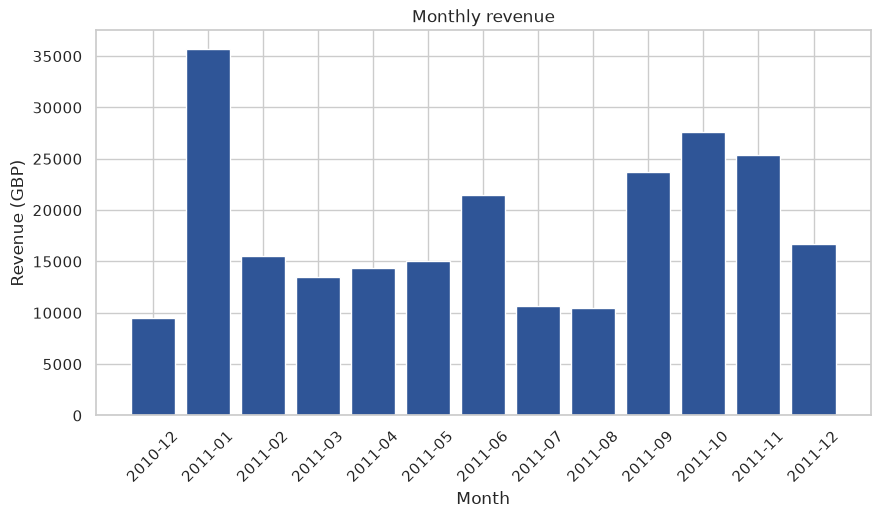

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(monthly.index, monthly["revenue"], color="#2F5597")
ax.set_title("Monthly revenue")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (GBP)")
ax.tick_params(axis="x", rotation=45)
plt.show()

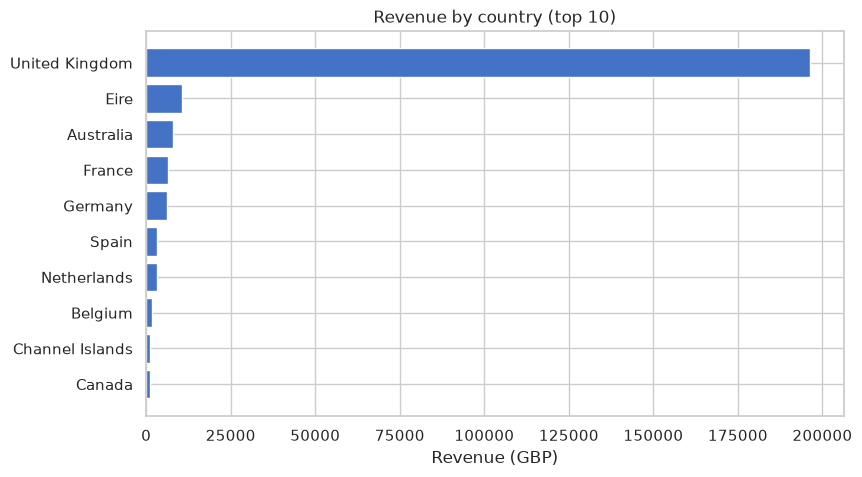

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
top = country.head(10)["revenue"].sort_values()
ax.barh(top.index, top.values, color="#4472C4")
ax.set_title("Revenue by country (top 10)")
ax.set_xlabel("Revenue (GBP)")
plt.show()

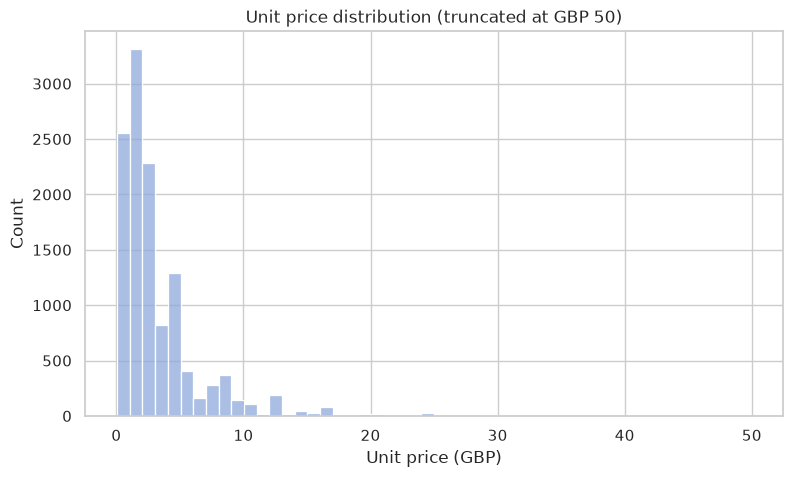

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df.loc[df["UnitPrice"] <= 50, "UnitPrice"], bins=50, ax=ax,
             color="#8FAADC")
ax.set_title("Unit price distribution (truncated at GBP 50)")
ax.set_xlabel("Unit price (GBP)")
plt.show()

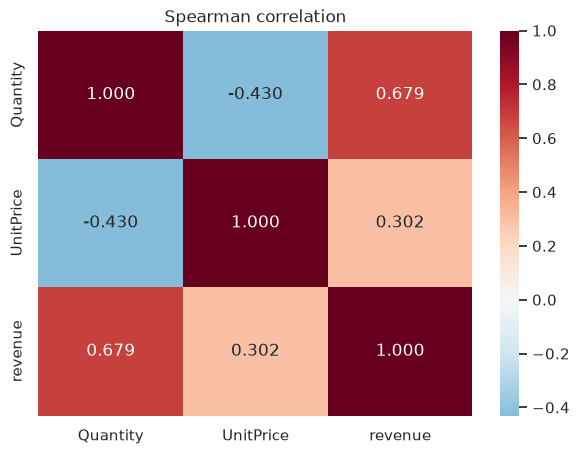

In [14]:
corr = df[["Quantity", "UnitPrice", "revenue"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Spearman correlation")
plt.show()

## 8. Statistical summary
A Welch t-test comparing UK and overseas line values, with the assumptions stated.

In [15]:
uk = df.loc[df["Country"] == "United Kingdom", "revenue"]
os_ = df.loc[df["Country"] != "United Kingdom", "revenue"]
t_stat, p = stats.ttest_ind(uk, os_, equal_var=False)
print(f"UK       n={len(uk):,}  mean {uk.mean():,.2f}")
print(f"Overseas n={len(os_):,}  mean {os_.mean():,.2f}")
print(f"Welch t = {t_stat:.3f}, p = {p:.3e}")
print("Decision:", "reject H0" if p < 0.05 else "do not reject H0")

UK       n=10,787  mean 18.21
Overseas n=1,390  mean 31.07
Welch t = -7.591, p = 4.835e-14
Decision: reject H0


## 9. Export the results
Writing analysis outputs to disk so other tools (SQL, Excel, Power BI) can consume them.

In [16]:
os.makedirs("../Jupyter_Lab/outputs", exist_ok=True)
monthly.to_csv("../Jupyter_Lab/outputs/monthly_summary.csv")
country.to_csv("../Jupyter_Lab/outputs/country_summary.csv")
print("written: outputs/monthly_summary.csv, outputs/country_summary.csv")

written: outputs/monthly_summary.csv, outputs/country_summary.csv


## 10. Reproducibility checklist
- [x] Random seed fixed (`RANDOM_STATE = 42`)
- [x] Package versions printed
- [x] Relative paths only
- [x] No hard-coded results — every figure is computed above
- [x] Outputs written to `outputs/`

**Exporting:** `File → Download as → Notebook (.ipynb)` or `jupyter nbconvert --to html`.